In [ ]:
import pandas as pd

# --- File paths ---
# Load the original NSL-KDD train and test files (multiclass version)
TRAIN_PATH = "KDDTrain+.txt"
TEST_PATH  = "KDDTest+.txt"

# --- Column names ---
# NSL-KDD contains 41 features + label + difficulty_level
cols = [
 'duration','protocol_type','service','flag','src_bytes','dst_bytes','land','wrong_fragment','urgent',
 'hot','num_failed_logins','logged_in','num_compromised','root_shell','su_attempted','num_root',
 'num_file_creations','num_shells','num_access_files','num_outbound_cmds','is_host_login','is_guest_login',
 'count','srv_count','serror_rate','srv_serror_rate','rerror_rate','srv_rerror_rate','same_srv_rate',
 'diff_srv_rate','srv_diff_host_rate','dst_host_count','dst_host_srv_count','dst_host_same_srv_rate',
 'dst_host_diff_srv_rate','dst_host_same_src_port_rate','dst_host_srv_diff_host_rate','dst_host_serror_rate',
 'dst_host_srv_serror_rate','dst_host_rerror_rate','dst_host_srv_rerror_rate','label','difficulty_level'
]

# --- Load train/test separately (no merging) ---
train = pd.read_csv(TRAIN_PATH, names=cols)
test = pd.read_csv(TEST_PATH, names=cols)

# --- Define attack category mapping ---
# NSL-KDD multiclass uses 5 categories: Normal, DoS, Probe, R2L, U2R
dos   = ['back','land','neptune','pod','smurf','teardrop']
probe = ['satan','ipsweep','nmap','portsweep']
r2l   = ['ftp_write','guess_passwd','imap','multihop','phf','spy','warezclient','warezmaster']
u2r   = ['buffer_overflow','loadmodule','perl','rootkit']

def map_attack(label):
    # Convert each attack name into its high-level attack category
    if label == 'normal': return 'Normal'
    elif label in dos:    return 'DoS'
    elif label in probe:  return 'Probe'
    elif label in r2l:    return 'R2L'
    elif label in u2r:    return 'U2R'
    else: return None     # For unknown/unmapped labels

# --- Apply mapping to train and test ---
train['target'] = train['label'].map(map_attack)
test['target']  = test['label'].map(map_attack)

# --- Drop rows with unknown/None targets ---
# Ensures only the 5 main classes remain
train = train.dropna(subset=['target'])
test  = test.dropna(subset=['target'])

# --- Drop irrelevant columns ---
# label and difficulty_level are not needed for training
train = train.drop(columns=['label','difficulty_level'])
test  = test.drop(columns=['label','difficulty_level'])

# --- Separate features and target ---
X_train = train.drop(columns=['target'])
y_train = train['target']

X_test = test.drop(columns=['target'])
y_test = test['target']

print("✅ Multiclass dataset loaded successfully")
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("\nClass distribution in TRAIN:\n", y_train.value_counts())
print("\nClass distribution in TEST:\n", y_test.value_counts())


✅ Multiclass dataset loaded successfully
Train shape: (110596, 41)  Test shape: (18794, 41)

Class distribution in TRAIN:
 target
Normal    59074
DoS       40363
Probe     10240
R2L         873
U2R          46
Name: count, dtype: int64

Class distribution in TEST:
 target
Normal    9711
DoS       5741
R2L       2199
Probe     1106
U2R         37
Name: count, dtype: int64


/tmp/ipython-input-2659309009.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=y_train.value_counts().index, y=y_train.value_counts().values, ax=axes[0], palette="crest")
/tmp/ipython-input-2659309009.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=y_test.value_counts().index, y=y_test.value_counts().values, ax=axes[1], palette="crest")


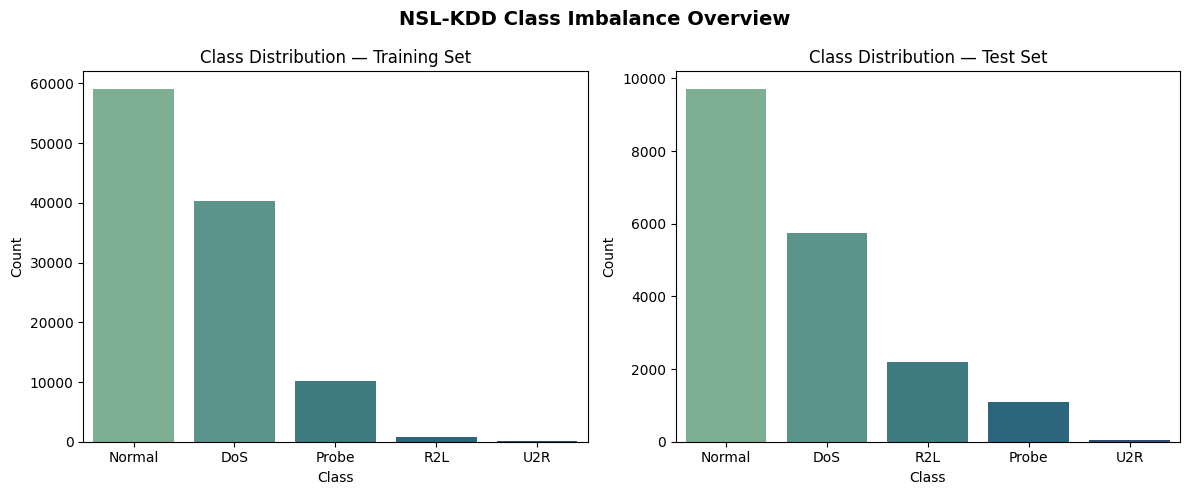

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Plot class distribution for training and test sets ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Training set class distribution
sns.barplot(
    x=y_train.value_counts().index,
    y=y_train.value_counts().values,
    ax=axes[0],
    palette="crest"
)
axes[0].set_title("Class Distribution — Training Set")
axes[0].set_ylabel("Count")
axes[0].set_xlabel("Class")

# Test set class distribution
sns.barplot(
    x=y_test.value_counts().index,
    y=y_test.value_counts().values,
    ax=axes[1],
    palette="crest"
)
axes[1].set_title("Class Distribution — Test Set")
axes[1].set_ylabel("Count")
axes[1].set_xlabel("Class")

# Overall figure title and formatting
plt.suptitle("NSL-KDD Class Imbalance Overview", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


In [ ]:
# STEP 2: Preprocessing Pipeline (ColumnTransformer + Scaling + Encoding)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# --- Identify feature types ---
# NSL-KDD has 3 categorical features; the remaining 38 are numerical
categorical_cols = ['protocol_type', 'service', 'flag']
numeric_cols = [col for col in X_train.columns if col not in categorical_cols]

print(f"Numeric features: {len(numeric_cols)} | Categorical features: {len(categorical_cols)}")

# --- Define preprocessing for numeric columns ---
# Steps:
# - Impute missing numeric values with the median
# - Standardize features (mean = 0, std = 1)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# --- Define preprocessing for categorical columns ---
# Steps:
# - Impute missing categories with the most frequent value
# - One-hot encode categorical features
# - ignore unknown categories during test-time evaluation
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# --- Combine both in a single ColumnTransformer ---
# This ensures:
# - numeric preprocessing applies only to numeric features
# - categorical preprocessing applies only to categorical ones
# - consistent and leak-free preprocessing during training and testing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

print("✅ Preprocessing pipeline built successfully")


Numeric features: 38 | Categorical features: 3
✅ Preprocessing pipeline built successfully


In [ ]:
# STEP 3: Logistic Regression (Multiclass) with CV

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score
import numpy as np

# --- Define model ---
# Multinomial logistic regression (softmax):
# - multi_class='multinomial' enables true softmax regression
# - lbfgs solver is recommended for multinomial problems
# - max_iter increased to ensure convergence on high-dimensional data
log_reg = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)

# --- Combine preprocessing + model ---
# Full ML pipeline:
# - Step 1: apply preprocessing (scaling + one-hot encoding)
# - Step 2: fit logistic regression classifier
pipe_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', log_reg)
])

# --- Define parameter grid ---
# Hyperparameters for tuning:
# - C controls strength of L2 regularization (smaller = stronger reg.)
# - class_weight balances minority classes if set to "balanced"
param_grid_lr = {
    'classifier__C': [0.1, 1, 10],
    'classifier__class_weight': [None, 'balanced']
}

# --- Stratified CV ---
# Ensures class proportions are preserved in each fold (important for imbalance)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --- GridSearchCV setup ---
# - f1_macro treats all classes equally, regardless of support (good for imbalance)
# - n_jobs=-1 uses all CPU cores for parallel search
# - verbose=2 prints progress
grid_lr = GridSearchCV(
    estimator=pipe_lr,
    param_grid=param_grid_lr,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

# --- Fit on KDDTrain+ only ---
# Grid search selects the best softmax regression model using cross-validation
grid_lr.fit(X_train, y_train)

print("\n✅ Logistic Regression cross-validation done.")
print("Best parameters:", grid_lr.best_params_)
print("Best mean CV F1_macro:", grid_lr.best_score_)

# --- Evaluate on KDDTest+ ---
# Predictions on unseen test data
y_pred = grid_lr.predict(X_test)

print("\nClassification Report (Test set):")
print(classification_report(y_test, y_pred, digits=3))

# Balanced accuracy accounts for class imbalance by averaging recall per class
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred))

# Display raw confusion matrix counts
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Fitting 5 folds for each of 6 candidates, totalling 30 fits


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



✅ Logistic Regression cross-validation done.
Best parameters: {'classifier__C': 10, 'classifier__class_weight': None}
Best mean CV F1_macro: 0.8581810388065158

Classification Report (Test set):
              precision    recall  f1-score   support

         DoS      0.945     0.989     0.967      5741
      Normal      0.802     0.930     0.861      9711
       Probe      0.754     0.976     0.851      1106
         R2L      0.959     0.032     0.062      2199
         U2R      0.778     0.378     0.509        37

    accuracy                          0.845     18794
   macro avg      0.848     0.661     0.650     18794
weighted avg      0.861     0.845     0.799     18794

Balanced Accuracy: 0.6611680504091149
Confusion Matrix:
 [[5677   62    2    0    0]
 [ 321 9034  350    2    4]
 [   4   22 1080    0    0]
 [   2 2127    0   70    0]
 [   2   20    0    1   14]]


In [ ]:
# STEP 4: Decision Tree Classifier (Multiclass)

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# --- Define model ---
# Decision Tree:
# - Non-linear classifier that recursively splits the feature space
# - random_state ensures reproducibility
dt = DecisionTreeClassifier(random_state=42)

# --- Combine preprocessing + model ---
# Full ML pipeline:
# - Step 1: apply preprocessing (scaling + one-hot encoding)
# - Step 2: fit Decision Tree classifier
pipe_dt = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', dt)
])

# --- Define parameter grid ---
# Hyperparameters for tuning:
# - max_depth controls how deep the tree can grow (None = full tree)
# - min_samples_leaf prevents overly small leaf nodes (reduces overfitting)
# - class_weight='balanced' helps with strong class imbalance
param_grid_dt = {
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_leaf': [1, 5, 10],
    'classifier__class_weight': [None, 'balanced']
}

# --- Stratified CV setup ---
# StratifiedKFold preserves class proportions in each fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --- GridSearchCV ---
# - Searches all combinations of tree hyperparameters
# - f1_macro gives equal importance to minority classes (important for U2R/R2L)
# - n_jobs=-1 parallelizes computation
grid_dt = GridSearchCV(
    estimator=pipe_dt,
    param_grid=param_grid_dt,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

# --- Fit on KDDTrain+ only ---
# Cross-validation selects the most generalizable Decision Tree
grid_dt.fit(X_train, y_train)

print("\n✅ Decision Tree cross-validation done.")
print("Best parameters:", grid_dt.best_params_)
print("Best mean CV F1_macro:", grid_dt.best_score_)

# --- Evaluate on test set ---
# Predict class labels on unseen test data
y_pred_dt = grid_dt.predict(X_test)

print("\nClassification Report (Test set):")
print(classification_report(y_test, y_pred_dt, digits=3))

# Balanced accuracy averages the recall of each class (good for imbalance)
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred_dt))

# Display confusion matrix counts
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))


Fitting 5 folds for each of 18 candidates, totalling 90 fits

✅ Decision Tree cross-validation done.
Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': 20, 'classifier__min_samples_leaf': 10}
Best mean CV F1_macro: 0.9068161436155684

Classification Report (Test set):
              precision    recall  f1-score   support

         DoS      0.985     0.981     0.983      5741
      Normal      0.811     0.923     0.864      9711
       Probe      0.594     0.981     0.740      1106
         R2L      0.969     0.085     0.157      2199
         U2R      0.714     0.135     0.227        37

    accuracy                          0.845     18794
   macro avg      0.815     0.621     0.594     18794
weighted avg      0.870     0.845     0.809     18794

Balanced Accuracy: 0.6211051862378554
Confusion Matrix:
 [[5632   46   63    0    0]
 [  72 8962  672    4    1]
 [  16    5 1085    0    0]
 [   0 2003    7  188    1]
 [   0   30    0    2    5]]


In [ ]:
# STEP 5: Random Forest Classifier (Multiclass)

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score

# --- Define model ---
# Random Forest:
# - Ensemble of decision trees using bootstrap aggregation (bagging)
# - n_jobs=-1 uses all CPU cores for faster training
# - random_state ensures reproducibility
rf = RandomForestClassifier(random_state=42, n_jobs=-1)

# --- Combine preprocessing + model ---
# Full pipeline:
# - Step 1: apply preprocessing
# - Step 2: fit Random Forest classifier
pipe_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', rf)
])

# --- Define parameter grid ---
# Hyperparameters for tuning:
# - n_estimators: number of trees (100 is a strong baseline)
# - max_depth: limits the depth of each tree (None = unrestricted)
# - min_samples_leaf: increases leaf size to reduce overfitting
# - class_weight='balanced' helps with severe class imbalance (U2R, R2L)
param_grid_rf = {
    'classifier__n_estimators': [100],        # fixed baseline
    'classifier__max_depth': [None, 20],
    'classifier__min_samples_leaf': [1, 5],
    'classifier__class_weight': [None, 'balanced']
}

# --- Stratified CV setup ---
# Ensures each fold maintains the same class distribution
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --- GridSearchCV ---
# - Performs exhaustive grid search over hyperparameters
# - f1_macro used to give equal importance to minority classes
# - n_jobs=-1 parallelizes the entire CV process
grid_rf = GridSearchCV(
    estimator=pipe_rf,
    param_grid=param_grid_rf,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

# --- Fit on KDDTrain+ only ---
# Cross-validation identifies the most generalizable Random Forest model
grid_rf.fit(X_train, y_train)

print("\n✅ Random Forest cross-validation done.")
print("Best parameters:", grid_rf.best_params_)
print("Best mean CV F1_macro:", grid_rf.best_score_)

# --- Evaluate on KDDTest+ ---
# Predict on unseen test data
y_pred_rf = grid_rf.predict(X_test)

print("\nClassification Report (Test set):")
print(classification_report(y_test, y_pred_rf, digits=3))

# Balanced accuracy = average recall per class (important for imbalance)
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred_rf))

# Display confusion matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))


Fitting 5 folds for each of 8 candidates, totalling 40 fits

✅ Random Forest cross-validation done.
Best parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 20, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}
Best mean CV F1_macro: 0.9157688055086325

Classification Report (Test set):
              precision    recall  f1-score   support

         DoS      0.988     0.985     0.987      5741
      Normal      0.834     0.971     0.897      9711
       Probe      0.795     0.999     0.885      1106
         R2L      0.986     0.157     0.271      2199
         U2R      0.455     0.270     0.339        37

    accuracy                          0.880     18794
   macro avg      0.811     0.677     0.676     18794
weighted avg      0.896     0.880     0.849     18794

Balanced Accuracy: 0.6765318779374212
Confusion Matrix:
 [[5656    6   79    0    0]
 [  67 9427  206    5    6]
 [   0    1 1105    0    0]
 [   0 1847    0  346    6]
 [   0   2

In [ ]:
# STEP 6: Softmax Regression (explicit multinomial logistic regression)

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score

# --- Define Softmax Regression model ---
# This is Logistic Regression in its true multinomial form:
# - multi_class='multinomial' activates the softmax function for multi-class output
# - lbfgs is a robust solver for multinomial objectives
# - max_iter increased to guarantee convergence on high-dimensional data
softmax = LogisticRegression(
    multi_class='multinomial',
    solver='lbfgs',
    max_iter=1000,
    random_state=42
)

# --- Combine preprocessing + model ---
# Pipeline ensures:
# - preprocessing is applied inside each CV fold (prevents data leakage)
# - consistent transformations during training & testing
pipe_softmax = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', softmax)
])

# --- Define parameter grid ---
# Hyperparameters to tune:
# - C controls L2 regularization (smaller = stronger regularization)
# - class_weight='balanced' helps adjust for class imbalance in NSL-KDD
param_grid_softmax = {
    'classifier__C': [0.1, 1, 10],
    'classifier__class_weight': [None, 'balanced']
}

# --- CV setup ---
# StratifiedKFold ensures each fold maintains the same class distribution.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --- GridSearchCV ---
# Performs an exhaustive hyperparameter search:
# - scoring='f1_macro' treats all classes equally (important for U2R/R2L imbalance)
# - n_jobs=-1 uses all CPU cores for faster training
# - verbose=2 prints progress during grid search
grid_softmax = GridSearchCV(
    estimator=pipe_softmax,
    param_grid=param_grid_softmax,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

# --- Fit on KDDTrain+ ---
# Fits the best Softmax model using cross-validation search.
grid_softmax.fit(X_train, y_train)

print("\n✅ Softmax Regression cross-validation done.")
print("Best parameters:", grid_softmax.best_params_)
print("Best mean CV F1_macro:", grid_softmax.best_score_)

# --- Evaluate on KDDTest+ ---
# Predictions on unseen data
y_pred_softmax = grid_softmax.predict(X_test)

print("\nClassification Report (Test set):")
print(classification_report(y_test, y_pred_softmax, digits=3))

# Balanced accuracy averages recall across all classes
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred_softmax))

# Confusion matrix for raw prediction counts
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_softmax))


Fitting 5 folds for each of 6 candidates, totalling 30 fits


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



✅ Softmax Regression cross-validation done.
Best parameters: {'classifier__C': 10, 'classifier__class_weight': None}
Best mean CV F1_macro: 0.8581810388065158

Classification Report (Test set):
              precision    recall  f1-score   support

         DoS      0.945     0.989     0.967      5741
      Normal      0.802     0.930     0.861      9711
       Probe      0.754     0.976     0.851      1106
         R2L      0.959     0.032     0.062      2199
         U2R      0.778     0.378     0.509        37

    accuracy                          0.845     18794
   macro avg      0.848     0.661     0.650     18794
weighted avg      0.861     0.845     0.799     18794

Balanced Accuracy: 0.6611680504091149
Confusion Matrix:
 [[5677   62    2    0    0]
 [ 321 9034  350    2    4]
 [   4   22 1080    0    0]
 [   2 2127    0   70    0]
 [   2   20    0    1   14]]


In [ ]:
# STEP 7: Gaussian Naïve Bayes (Multiclass)

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score
from sklearn.pipeline import Pipeline

# --- Define model ---
# Gaussian Naïve Bayes:
# - Assumes each feature follows a class-conditional Gaussian distribution
# - Strong independence assumption between features
# - Very fast and low-variance model, but often underperforms on correlated features
nb = GaussianNB()

# --- Pipeline: preprocessing + model ---
# Ensures preprocessing is applied consistently in both training and evaluation
pipe_nb = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', nb)
])

# --- Stratified 5-fold CV ---
# StratifiedKFold preserves class proportions across folds (important for NSL-KDD imbalance)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Cross-validation using macro F1:
# - macro F1 treats all classes equally (critical for U2R/R2L minority classes)
cv_scores = cross_val_score(
    pipe_nb, X_train, y_train,
    scoring='f1_macro', cv=cv, n_jobs=-1
)

print("✅ Gaussian Naïve Bayes cross-validation done.")
print(f"Mean CV F1_macro = {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

# --- Fit on full training data ---
# Fit pipeline on the entire training set after CV evaluation
pipe_nb.fit(X_train, y_train)

# --- Evaluate on KDDTest+ ---
# Predictions on unseen test data
y_pred_nb = pipe_nb.predict(X_test)

print("\nClassification Report (Test set):")
print(classification_report(y_test, y_pred_nb, digits=3))

# Balanced accuracy averages recall across classes (robust to imbalance)
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred_nb))

# Confusion matrix for detailed class-level prediction errors
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))


✅ Gaussian Naïve Bayes cross-validation done.
Mean CV F1_macro = 0.4333 ± 0.0243

Classification Report (Test set):
              precision    recall  f1-score   support

         DoS      0.971     0.580     0.726      5741
      Normal      0.647     0.679     0.663      9711
       Probe      0.900     0.186     0.309      1106
         R2L      0.234     0.422     0.301      2199
         U2R      0.026     0.676     0.050        37

    accuracy                          0.590     18794
   macro avg      0.556     0.509     0.410     18794
weighted avg      0.712     0.590     0.618     18794

Balanced Accuracy: 0.5087330547794979
Confusion Matrix:
 [[3330 2082   13  287   29]
 [  77 6596   10 2740  288]
 [  21  751  206    8  120]
 [   0  761    0  929  509]
 [   0    1    0   11   25]]


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, balanced_accuracy_score

# List to store all model results for final comparison
results = []

# Helper function to append metrics for each model
# - name: model name
# - cv_score: best cross-validation F1_macro score
# - y_true, y_pred: true and predicted labels on the test set
def add_result(name, cv_score, y_true, y_pred):
    results.append({
        "Model": name,
        "CV_F1_macro": cv_score,                                 # Cross-validation F1_macro
        "Test_Accuracy": accuracy_score(y_true, y_pred),         # Raw accuracy
        "Test_F1_macro": f1_score(y_true, y_pred, average="macro"),     # Equal weight to all classes
        "Test_F1_weighted": f1_score(y_true, y_pred, average="weighted"), # Weighted by class frequency
        "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred)      # Accounts for imbalance
    })

# --- Add results for each model ---

# Naïve Bayes
add_result(
    "Naive Bayes (Gaussian)",
    cv_scores.mean(),
    y_test, y_pred_nb
)

# Softmax Regression (multinomial logistic regression)
add_result(
    "Softmax Regression",
    grid_softmax.best_score_,
    y_test, y_pred_softmax
)

# Decision Tree
add_result(
    "Decision Tree",
    grid_dt.best_score_,
    y_test, y_pred_dt
)

# Random Forest
add_result(
    "Random Forest",
    grid_rf.best_score_,
    y_test, y_pred_rf
)

# Convert results list to a DataFrame for easy comparison
results_df = pd.DataFrame(results)
print(results_df)


                    Model  CV_F1_macro  Test_Accuracy  Test_F1_macro  \
0  Naive Bayes (Gaussian)     0.433343       0.589869       0.409673   
1      Softmax Regression     0.858181       0.844684       0.649937   
2           Decision Tree     0.906816       0.844525       0.594116   
3           Random Forest     0.915769       0.880281       0.675902   

   Test_F1_weighted  Balanced_Accuracy  
0          0.617850           0.508733  
1          0.798620           0.661168  
2          0.808776           0.621105  
3          0.849430           0.676532  


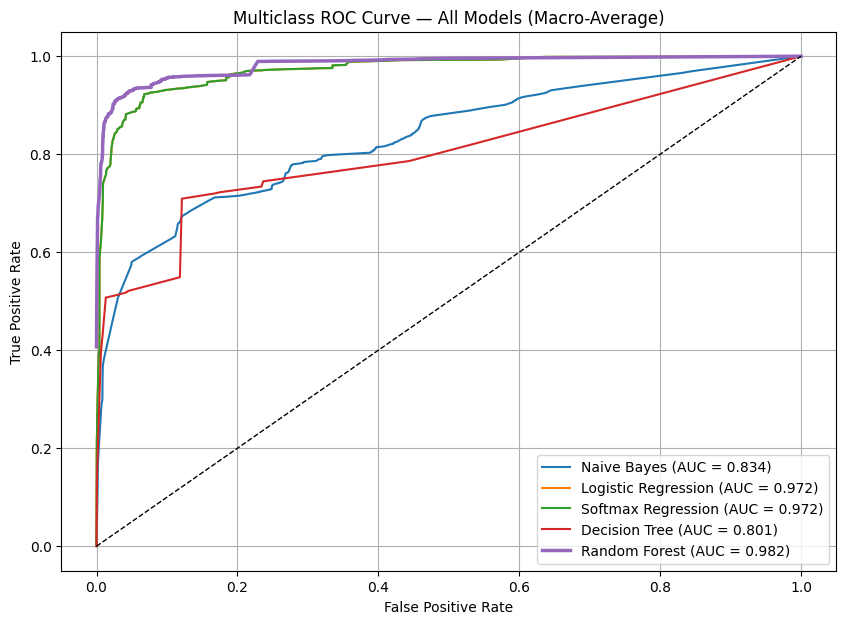

In [ ]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import numpy as np

def macro_roc_auc_curve(y_true, y_score, classes):
    """Returns macro-average ROC curve (fpr, tpr) and AUC.

    Steps:
    - Binarize true labels (one-vs-rest representation)
    - Compute ROC curve per class
    - Compute macro-average by interpolating and averaging TPRs across classes
    """

    # One-vs-rest binarization for multiclass ROC
    y_true_bin = label_binarize(y_true, classes=classes)
    n_classes = len(classes)

    fpr = {}
    tpr = {}
    roc_auc = {}

    # --- ROC curve for each class ---
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # --- Macro-average ROC computation ---
    # Aggregate all FPR points
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))

    # Average TPR across all classes
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])  # interpolate at common FPR points

    mean_tpr /= n_classes
    macro_auc = auc(all_fpr, mean_tpr)

    return all_fpr, mean_tpr, macro_auc


# --- Classes in sorted order ---
classes = sorted(y_train.unique())

# --- Collect predicted probabilities from all models ---
# Needed for ROC curves (probabilities, not class labels)
proba_nb = pipe_nb.predict_proba(X_test)
proba_lr = grid_lr.best_estimator_.predict_proba(X_test)
proba_softmax = grid_softmax.best_estimator_.predict_proba(X_test)
proba_dt = grid_dt.best_estimator_.predict_proba(X_test)
proba_rf = grid_rf.best_estimator_.predict_proba(X_test)

# --- Compute macro-average ROC curves for all models ---
fpr_nb, tpr_nb, auc_nb = macro_roc_auc_curve(y_test, proba_nb, classes)
fpr_lr, tpr_lr, auc_lr = macro_roc_auc_curve(y_test, proba_lr, classes)
fpr_soft, tpr_soft, auc_soft = macro_roc_auc_curve(y_test, proba_softmax, classes)
fpr_dt, tpr_dt, auc_dt = macro_roc_auc_curve(y_test, proba_dt, classes)
fpr_rf, tpr_rf, auc_rf = macro_roc_auc_curve(y_test, proba_rf, classes)

# --- Plot all ROC curves ---
plt.figure(figsize=(10,7))

plt.plot(fpr_nb, tpr_nb, label=f"Naive Bayes (AUC = {auc_nb:.3f})")
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.3f})")
plt.plot(fpr_soft, tpr_soft, label=f"Softmax Regression (AUC = {auc_soft:.3f})")
plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree (AUC = {auc_dt:.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})", linewidth=2.5)

# Random classifier baseline
plt.plot([0,1],[0,1],"k--",linewidth=1)

# Plot formatting
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve — All Models (Macro-Average)")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


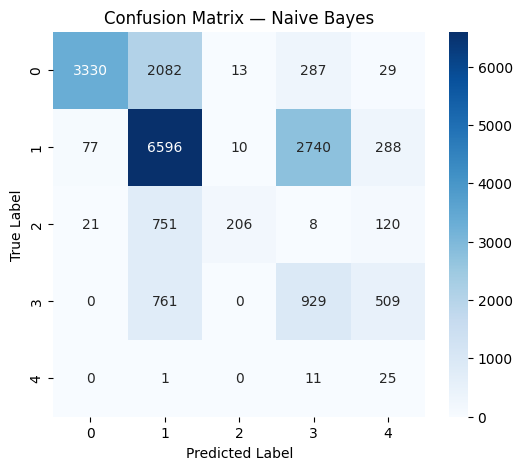

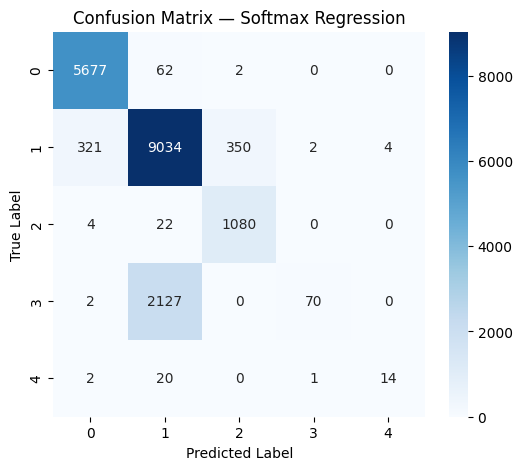

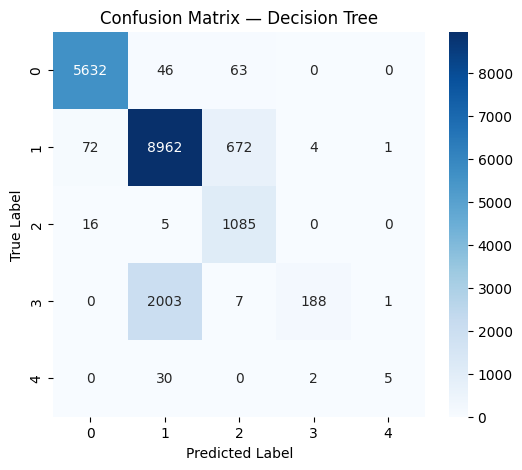

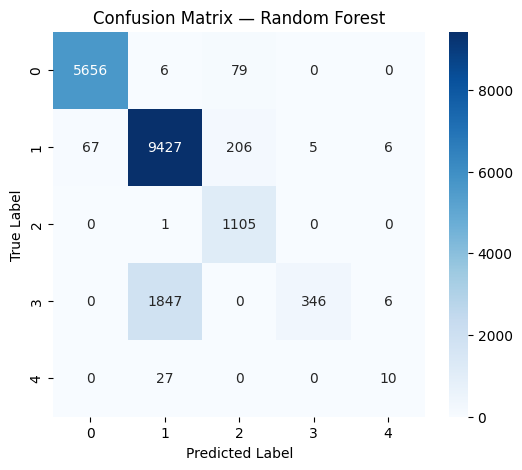

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Helper function to plot a labeled confusion matrix using seaborn
def plot_cm(model_name, y_true, y_pred):
    # Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    # Create heatmap
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

    # Titles and axis labels
    plt.title(f"Confusion Matrix — {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()

# ---- Plot confusion matrices for each model ----
plot_cm("Naive Bayes", y_test, y_pred_nb)
plot_cm("Softmax Regression", y_test, y_pred_softmax)
plot_cm("Decision Tree", y_test, y_pred_dt)
plot_cm("Random Forest", y_test, y_pred_rf)
